
=== f1(x) = x^3 - 3x^2 + 2, X = [0, 3] ===
Метод                     Интервал                                           rad         d_H
--------------------------------------------------------------------------------------------
natural                   [-25.000000000, 29.000000000]                27.000000   27.000000
transformed               [-6.000000000, 3.000000000]                   4.500000    4.000000
mean c=0.75               [-6.015625000, 20.984375000]                 13.500000   18.984375
mean c=1.5                [-14.875000000, 12.125000000]                13.500000   12.875000
mean c=2.25               [-22.046875000, 4.953125000]                 13.500000   20.046875
slope c=0.75              [-5.910156250, 2.949218750]                   4.429688    3.910156
slope c=1.5               [-5.593750000, 2.843750000]                   4.218750    3.593750
slope c=2.25              [-13.187500000, 2.316406250]                  7.751953   11.187500
Baumann                   

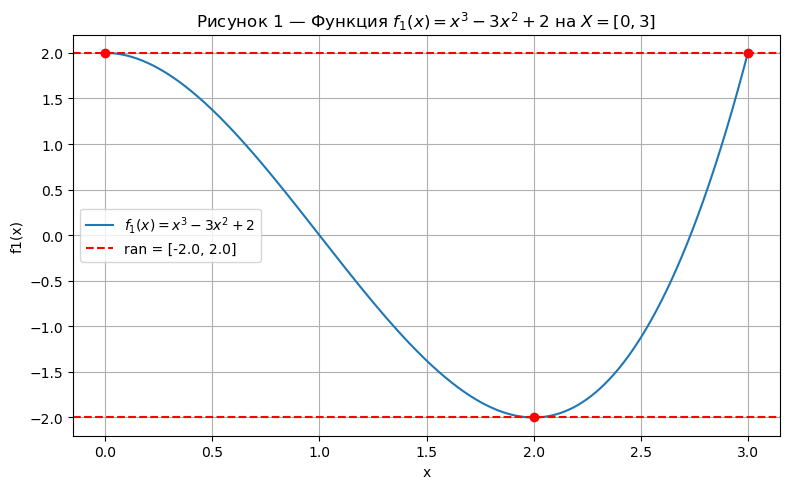

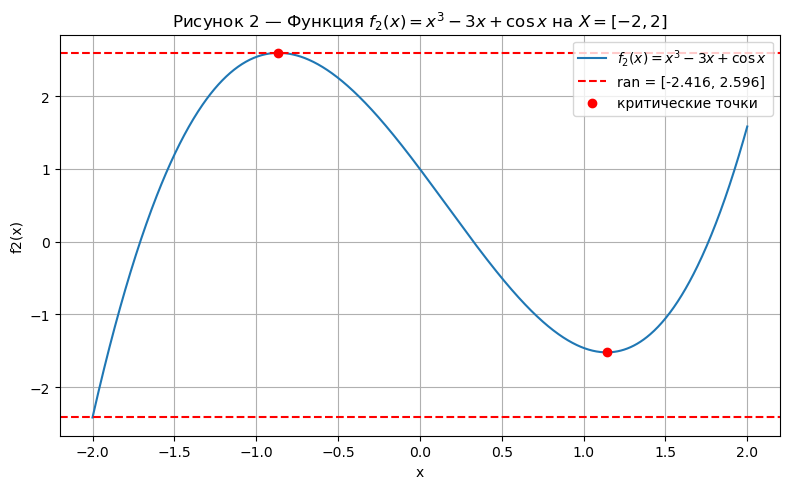

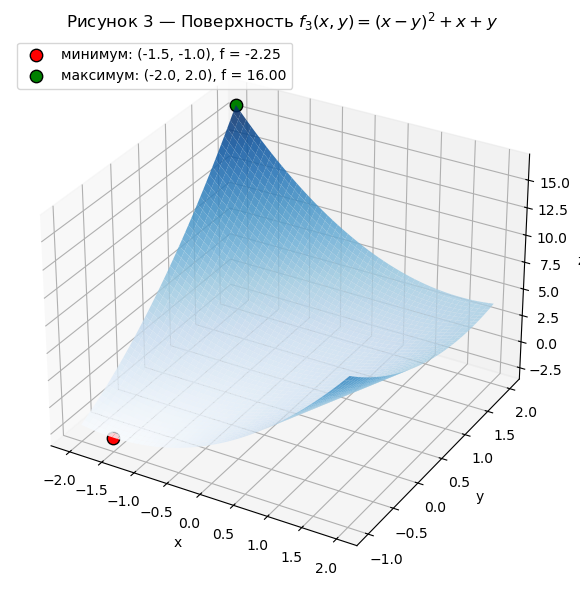

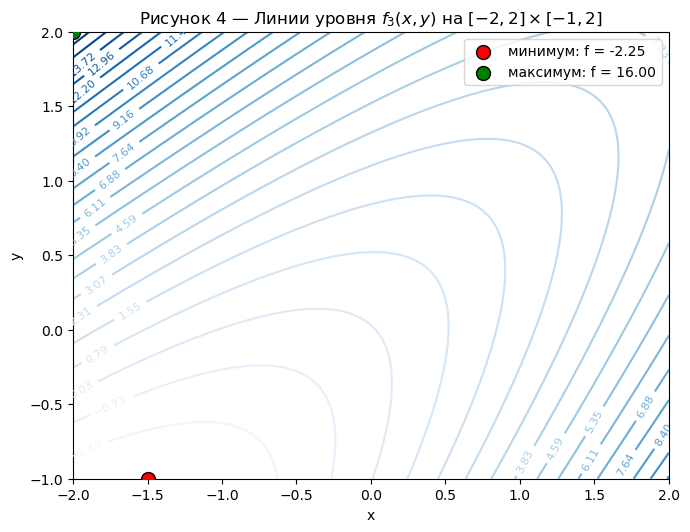


=== 4.4. Дробление бруса для f3 ===

Разбиение по x (в точке x = 0.0):
  подбрус 1: [-2.0, 0.0] x [-1.0, 2.0]  ->  F = [-3.0000, 18.0000]
  подбрус 2: [0.0, 2.0] x [-1.0, 2.0]  ->  F = [-1.0000, 13.0000]
  оболочка:  [-3.0000, 18.0000]  d_H = 2.0000

Разбиение по y (в точке y = 0.5):
  подбрус 1: [-2.0, 2.0] x [-1.0, 0.5]  ->  F = [-3.0000, 11.5000]
  подбрус 2: [-2.0, 2.0] x [0.5, 2.0]  ->  F = [-1.5000, 20.0000]
  оболочка:  [-3.0000, 20.0000]  d_H = 4.0000

НИР на исходном брусе: [-3.0000, 20.0000]  d_H = 4.0000


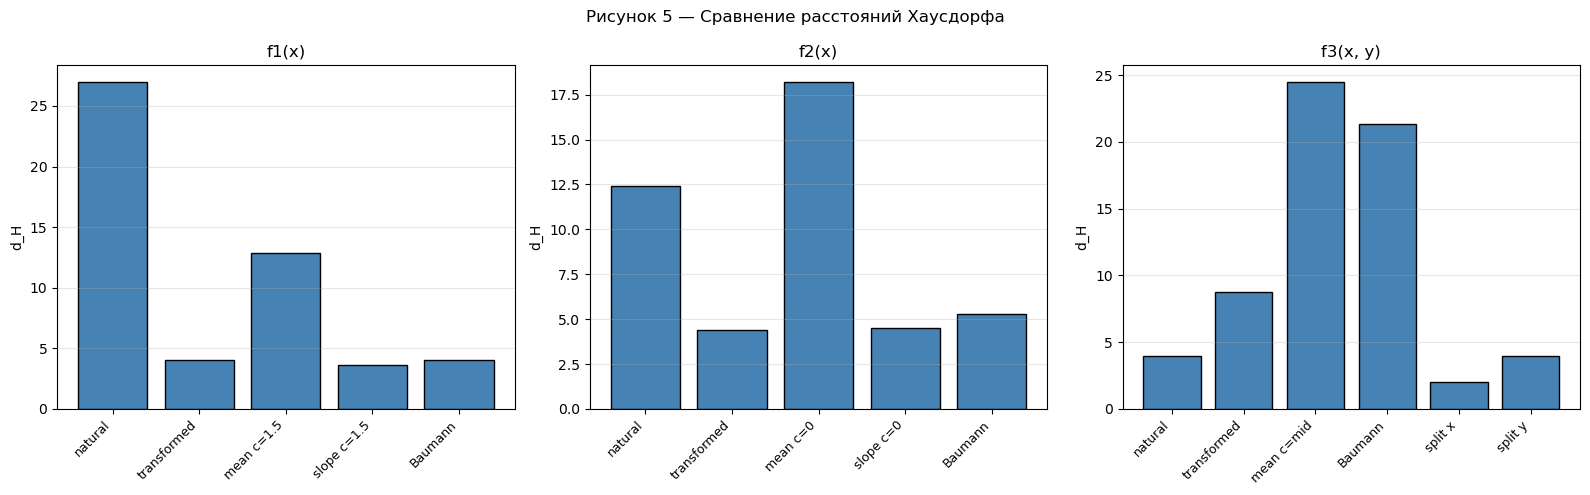

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from math import sin, cos
from scipy.optimize import brentq, minimize_scalar

# ============================================================
# Интервальная арифметика
# ============================================================
def iadd(A, B): return A[0] + B[0], A[1] + B[1]
def isub(A, B): return A[0] - B[1], A[1] - B[0]
def imul(A, B):
    v = [A[0]*B[0], A[0]*B[1], A[1]*B[0], A[1]*B[1]]
    return min(v), max(v)
def iscale(k, A):
    return (k*A[0], k*A[1]) if k >= 0 else (k*A[1], k*A[0])
def square(A):
    a, b = A
    if a <= 0 <= b: return 0.0, max(a*a, b*b)
    return min(a*a, b*b), max(a*a, b*b)
def cube(A): return A[0]**3, A[1]**3
def radius(A): return (A[1] - A[0]) / 2
def hausdorff(A, B): return max(abs(A[0]-B[0]), abs(A[1]-B[1]))
def intersection(A, B): return max(A[0], B[0]), min(A[1], B[1])
def hull(A, B): return min(A[0], B[0]), max(A[1], B[1])

def cos_interval(A):
    a, b = A
    pts = [a, b]
    if a <= 0 <= b: pts.append(0.0)
    if a <= np.pi <= b: pts.append(np.pi)
    if a <= -np.pi <= b: pts.append(-np.pi)
    vals = [cos(p) for p in pts]
    return min(vals), max(vals)

def sin_interval(A):
    a, b = A
    pts = [a, b]
    if a <= np.pi/2 <= b: pts.append(np.pi/2)
    if a <= -np.pi/2 <= b: pts.append(-np.pi/2)
    vals = [sin(p) for p in pts]
    return min(vals), max(vals)

# ============================================================
# Вспомогательные функции
# ============================================================
def find_roots(fun, a, b, n=20000):
    xs = np.linspace(a, b, n + 1)
    roots = []
    for x1, x2 in zip(xs[:-1], xs[1:]):
        y1, y2 = fun(x1), fun(x2)
        if abs(y1) < 1e-13: roots.append(x1)
        elif y1 * y2 < 0: roots.append(brentq(fun, x1, x2))
    result = []
    for r in roots:
        if not result or abs(r - result[-1]) > 1e-8:
            result.append(r)
    return result

def numerical_range(fun, a, b, n=30000):
    xs = np.linspace(a, b, n + 1)
    ys = np.array([fun(x) for x in xs])
    i_min, i_max = np.argmin(ys), np.argmax(ys)
    def refine(i, sign):
        if i == 0 or i == len(xs) - 1: return xs[i], ys[i]
        r = minimize_scalar(lambda z: sign*fun(z), bounds=(xs[i-1], xs[i+1]), method='bounded')
        return r.x, fun(r.x)
    mn = min([refine(i_min, +1), (a, fun(a)), (b, fun(b))], key=lambda p: p[1])[1]
    mx = max([refine(i_max, -1), (a, fun(a)), (b, fun(b))], key=lambda p: p[1])[1]
    return mn, mx

def mean_form(f, X, c, D):
    return iadd((f(c), f(c)), imul(D, (X[0]-c, X[1]-c)))

def baumann_centers(X, D):
    a, b = X
    L, U = D
    if U == L: return (a+b)/2, (a+b)/2
    c_m = (a*U - b*L) / (U - L)
    c_p = (b*U - a*L) / (U - L)
    return c_m, c_p

def print_results(title, exact, rows):
    print("\n" + title)
    print(f"{'Метод':<26}{'Интервал':<42}{'rad':>12}{'d_H':>12}")
    print("-" * 92)
    for name, I in rows:
        txt = f"[{I[0]:.9f}, {I[1]:.9f}]"
        print(f"{name:<26}{txt:<42}{radius(I):>12.6f}{hausdorff(I, exact):>12.6f}")

# ============================================================
# f1(x) = x^3 - 3x^2 + 2, X = [0, 3]
# ============================================================
def f1(x): return x**3 - 3*x**2 + 2
def df1(x): return 3*x**2 - 6*x

X1 = (0.0, 3.0)
points1 = [0.0, 2.0, 3.0]
R1 = min(f1(x) for x in points1), max(f1(x) for x in points1)

F1_nat = iadd(iadd(cube(X1), iscale(-3, square(X1))), (2, 2))
Xm1 = isub(X1, (1, 1))
F1_trans = isub(imul(Xm1, isub(square(Xm1), (3, 3))), (0, 0))

D1 = (-3.0, 9.0)
centers1 = [0.75, 1.5, 2.25]
F1_mv = {c: mean_form(f1, X1, c, D1) for c in centers1}

def slope1(x, c): return x**2 + (c - 3)*x + c**2 - 3*c
S1 = {c: numerical_range(lambda x, c=c: slope1(x, c), *X1) for c in centers1}
F1_sl = {c: iadd((f1(c), f1(c)), imul(S1[c], (X1[0]-c, X1[1]-c))) for c in centers1}

c1m, c1p = baumann_centers(X1, D1)
F1_B = intersection(mean_form(f1, X1, c1m, D1), mean_form(f1, X1, c1p, D1))

# ============================================================
# f2(x) = x^3 - 3x + cos(x), X = [-2, 2]
# ============================================================
def f2(x): return x**3 - 3*x + cos(x)
def df2(x): return 3*x**2 - 3 - sin(x)
def ddf2(x): return 6*x + cos(x)

X2 = (-2.0, 2.0)

# Точная область через плотную сетку
xs_dense = np.linspace(X2[0], X2[1], 100000)
ys_dense = np.array([f2(x) for x in xs_dense])
R2 = (ys_dense.min(), ys_dense.max())

# Критические точки (для графика и для D2)
critical2 = find_roots(df2, *X2)

# НИР исходного
F2_nat = iadd(iadd(cube(X2), iscale(-3, X2)), cos_interval(X2))

# Эквивалентное: x(x^2 - 3) + cos(x)
F2_trans = iadd(imul(X2, isub(square(X2), (3, 3))), cos_interval(X2))

# Диапазон производной — через плотную сетку
xs_d2 = np.linspace(X2[0], X2[1], 100000)
ys_d2 = np.array([df2(x) for x in xs_d2])
D2 = (ys_d2.min(), ys_d2.max())

centers2 = [-1.0, 0.0, 1.0]
F2_mv = {c: mean_form(f2, X2, c, D2) for c in centers2}

def slope2(x, c):
    if abs(x - c) < 1e-10: return df2(c)
    return (f2(x) - f2(c)) / (x - c)

S2 = {c: numerical_range(lambda x, c=c: slope2(x, c), *X2) for c in centers2}
F2_sl = {c: iadd((f2(c), f2(c)), imul(S2[c], (X2[0]-c, X2[1]-c))) for c in centers2}

c2m, c2p = baumann_centers(X2, D2)
F2_B = intersection(mean_form(f2, X2, c2m, D2), mean_form(f2, X2, c2p, D2))

# ============================================================
# f3(x, y) = (x - y)^2 + x + y, X = [-2, 2] x [-1, 2]
# ============================================================
def f3(x, y): return (x - y)**2 + x + y
def fx3(x, y): return 2*(x - y) + 1
def fy3(x, y): return -2*(x - y) + 1

X3 = ((-2.0, 2.0), (-1.0, 2.0))

# Точная область через плотную сетку
xs3 = np.linspace(X3[0][0], X3[0][1], 500)
ys3 = np.linspace(X3[1][0], X3[1][1], 500)
Xg3, Yg3 = np.meshgrid(xs3, ys3)
Zg3 = (Xg3 - Yg3)**2 + Xg3 + Yg3
R3 = (Zg3.min(), Zg3.max())

# НИР исходного: (x - y)^2 + x + y
XmY = isub(X3[0], X3[1])
F3_nat = iadd(iadd(square(XmY), X3[0]), X3[1])

# Эквивалентное: x^2 - 2xy + y^2 + x + y
F3_trans = iadd(
    iadd(iadd(square(X3[0]), iscale(-2, imul(X3[0], X3[1]))), square(X3[1])),
    iadd(X3[0], X3[1])
)

# Точный диапазон производных (линейные)
Dx_interval = (min(fx3(x, y) for x in X3[0] for y in X3[1]),
               max(fx3(x, y) for x in X3[0] for y in X3[1]))
Dy_interval = (min(fy3(x, y) for x in X3[0] for y in X3[1]),
               max(fy3(x, y) for x in X3[0] for y in X3[1]))

def mv3(cx, cy):
    return iadd(
        iadd((f3(cx, cy), f3(cx, cy)), imul(Dx_interval, (X3[0][0]-cx, X3[0][1]-cx))),
        imul(Dy_interval, (X3[1][0]-cy, X3[1][1]-cy))
    )

c_mid = ((X3[0][0]+X3[0][1])/2, (X3[1][0]+X3[1][1])/2)
c_min = (0.5, -0.5)
F3_mv_mid = mv3(*c_mid)
F3_mv_min = mv3(*c_min)

cx_m, cx_p = baumann_centers(X3[0], Dx_interval)
cy_m, cy_p = baumann_centers(X3[1], Dy_interval)
F3_bic = intersection(mv3(cx_m, cy_m), mv3(cx_p, cy_p))

def nir_brus(Xx, Yy):
    XmY = isub(Xx, Yy)
    return iadd(iadd(square(XmY), Xx), Yy)

mid_x = (X3[0][0] + X3[0][1]) / 2
mid_y = (X3[1][0] + X3[1][1]) / 2
F3_split_x = hull(nir_brus((X3[0][0], mid_x), X3[1]), nir_brus((mid_x, X3[0][1]), X3[1]))
F3_split_y = hull(nir_brus(X3[0], (X3[1][0], mid_y)), nir_brus(X3[0], (mid_y, X3[1][1])))

L1_3 = max(abs(Dx_interval[0]), abs(Dx_interval[1]))
L2_3 = max(abs(Dy_interval[0]), abs(Dy_interval[1]))

# ============================================================
# Вывод результатов
# ============================================================
rows1 = [
    ("natural", F1_nat),
    ("transformed", F1_trans),
    *[(f"mean c={c}", F1_mv[c]) for c in centers1],
    *[(f"slope c={c}", F1_sl[c]) for c in centers1],
    ("Baumann", F1_B),
]
rows2 = [
    ("natural", F2_nat),
    ("transformed", F2_trans),
    *[(f"mean c={c}", F2_mv[c]) for c in centers2],
    *[(f"slope c={c}", F2_sl[c]) for c in centers2],
    ("Baumann", F2_B),
]
rows3 = [
    ("natural", F3_nat),
    ("transformed", F3_trans),
    ("mean c=mid", F3_mv_mid),
    ("mean c=(0.5,-0.5)", F3_mv_min),
    ("Baumann", F3_bic),
    ("split x", F3_split_x),
    ("split y", F3_split_y),
]

print_results("=== f1(x) = x^3 - 3x^2 + 2, X = [0, 3] ===", R1, rows1)
print(f"  Точная область: [{R1[0]:.6f}, {R1[1]:.6f}]")
print(f"  L = {max(abs(D1[0]), abs(D1[1]))}  |  L*rad X = {max(abs(D1[0]), abs(D1[1]))*radius(X1):.4f}  |  rad(NIR) = {radius(F1_nat):.4f}")

print_results("=== f2(x) = x^3 - 3x + cos(x), X = [-2, 2] ===", R2, rows2)
print(f"  Точная область: [{R2[0]:.6f}, {R2[1]:.6f}]")
print(f"  L = {max(abs(D2[0]), abs(D2[1])):.4f}  |  L*rad X = {max(abs(D2[0]), abs(D2[1]))*radius(X2):.4f}  |  rad(NIR) = {radius(F2_nat):.4f}")

print_results("=== f3(x,y) = (x-y)^2 + x + y, X = [-2,2] x [-1,2] ===", R3, rows3)
print(f"  Точная область: [{R3[0]:.6f}, {R3[1]:.6f}]")
print(f"  L1 = {L1_3}, L2 = {L2_3}")
print(f"  L1*radX1 + L2*radX2 = {L1_3*radius(X3[0]) + L2_3*radius(X3[1]):.4f}  |  rad(NIR) = {radius(F3_nat):.4f}")

# ============================================================
# Графики
# ============================================================
# f1
xx = np.linspace(*X1, 1000)
plt.figure(figsize=(8, 5))
plt.plot(xx, [f1(x) for x in xx], label=r"$f_1(x) = x^3 - 3x^2 + 2$")
plt.axhline(R1[0], color="r", linestyle="--", label=f"ran = [{R1[0]}, {R1[1]}]")
plt.axhline(R1[1], color="r", linestyle="--")
plt.scatter(points1, [f1(x) for x in points1], color="r", zorder=5)
plt.title(r"Рисунок 1 — Функция $f_1(x) = x^3 - 3x^2 + 2$ на $X = [0, 3]$")
plt.xlabel("x"); plt.ylabel("f1(x)"); plt.grid(); plt.legend()
plt.tight_layout(); plt.show()

# f2
xx = np.linspace(*X2, 1000)
plt.figure(figsize=(8, 5))
plt.plot(xx, [f2(x) for x in xx], label=r"$f_2(x) = x^3 - 3x + \cos x$")
plt.axhline(R2[0], color="r", linestyle="--", label=f"ran = [{R2[0]:.3f}, {R2[1]:.3f}]")
plt.axhline(R2[1], color="r", linestyle="--")
plt.scatter(critical2, [f2(x) for x in critical2], color="r", zorder=5, label="критические точки")
plt.title(r"Рисунок 2 — Функция $f_2(x) = x^3 - 3x + \cos x$ на $X = [-2, 2]$")
plt.xlabel("x"); plt.ylabel("f2(x)"); plt.grid(); plt.legend()
plt.tight_layout(); plt.show()

# Точки min и max (найдены численно)
x_min, y_min = -1.5, -1.0
z_min = f3(x_min, y_min)

x_max, y_max = -2.0, 2.0
z_max = f3(x_max, y_max)

# ============================================================
# Рисунок 3 — поверхность f3 с отмеченными min и max
# ============================================================
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Xg3, Yg3, Zg3, cmap="Blues", edgecolor="none", alpha=0.85)
ax.scatter(x_min, y_min, z_min, color="red", s=80, edgecolor="black",
           label=f"минимум: ({x_min}, {y_min}), f = {z_min:.2f}")
ax.scatter(x_max, y_max, z_max, color="green", s=80, edgecolor="black",
           label=f"максимум: ({x_max}, {y_max}), f = {z_max:.2f}")
ax.set(xlabel="x", ylabel="y", zlabel="z")
ax.set_title(r"Рисунок 3 — Поверхность $f_3(x, y) = (x-y)^2 + x + y$")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

# ============================================================
# Рисунок 4 — линии уровня f3 с min и max
# ============================================================
fig, ax = plt.subplots(figsize=(7, 6))
levels = np.linspace(Zg3.min(), Zg3.max(), 25)
cs = ax.contour(Xg3, Yg3, Zg3, levels=levels, cmap="Blues")
ax.clabel(cs, inline=True, fontsize=8)
ax.scatter(x_min, y_min, color="red", s=100, edgecolor="black", zorder=5,
           label=f"минимум: f = {z_min:.2f}")
ax.scatter(x_max, y_max, color="green", s=100, edgecolor="black", zorder=5,
           label=f"максимум: f = {z_max:.2f}")
ax.set(xlabel="x", ylabel="y", aspect="equal")
ax.set_title(r"Рисунок 4 — Линии уровня $f_3(x, y)$ на $[-2,2] \times [-1,2]$")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

print("\n=== 4.4. Дробление бруса для f3 ===\n")

mid_x = (X3[0][0] + X3[0][1]) / 2
mid_y = (X3[1][0] + X3[1][1]) / 2

# Дробление по x
Fx1 = nir_brus((X3[0][0], mid_x), X3[1])
Fx2 = nir_brus((mid_x, X3[0][1]), X3[1])
Fx_hull = hull(Fx1, Fx2)

print("Разбиение по x (в точке x = {}):".format(mid_x))
print(f"  подбрус 1: [{X3[0][0]}, {mid_x}] x [{X3[1][0]}, {X3[1][1]}]  ->  F = [{Fx1[0]:.4f}, {Fx1[1]:.4f}]")
print(f"  подбрус 2: [{mid_x}, {X3[0][1]}] x [{X3[1][0]}, {X3[1][1]}]  ->  F = [{Fx2[0]:.4f}, {Fx2[1]:.4f}]")
print(f"  оболочка:  [{Fx_hull[0]:.4f}, {Fx_hull[1]:.4f}]  d_H = {hausdorff(Fx_hull, R3):.4f}")

# Дробление по y
Fy1 = nir_brus(X3[0], (X3[1][0], mid_y))
Fy2 = nir_brus(X3[0], (mid_y, X3[1][1]))
Fy_hull = hull(Fy1, Fy2)

print(f"\nРазбиение по y (в точке y = {mid_y}):")
print(f"  подбрус 1: [{X3[0][0]}, {X3[0][1]}] x [{X3[1][0]}, {mid_y}]  ->  F = [{Fy1[0]:.4f}, {Fy1[1]:.4f}]")
print(f"  подбрус 2: [{X3[0][0]}, {X3[0][1]}] x [{mid_y}, {X3[1][1]}]  ->  F = [{Fy2[0]:.4f}, {Fy2[1]:.4f}]")
print(f"  оболочка:  [{Fy_hull[0]:.4f}, {Fy_hull[1]:.4f}]  d_H = {hausdorff(Fy_hull, R3):.4f}")

print(f"\nНИР на исходном брусе: [{F3_nat[0]:.4f}, {F3_nat[1]:.4f}]  d_H = {hausdorff(F3_nat, R3):.4f}")


# Сводный график d_H для всех методов на трёх функциях
methods_f1 = ["natural", "transformed", "mean c=1.5", "slope c=1.5", "Baumann"]
dh_f1 = [hausdorff(F1_nat, R1), hausdorff(F1_trans, R1),
         hausdorff(F1_mv[1.5], R1), hausdorff(F1_sl[1.5], R1), hausdorff(F1_B, R1)]

methods_f2 = ["natural", "transformed", "mean c=0", "slope c=0", "Baumann"]
dh_f2 = [hausdorff(F2_nat, R2), hausdorff(F2_trans, R2),
         hausdorff(F2_mv[0.0], R2), hausdorff(F2_sl[0.0], R2), hausdorff(F2_B, R2)]

methods_f3 = ["natural", "transformed", "mean c=mid", "Baumann", "split x", "split y"]
dh_f3 = [hausdorff(F3_nat, R3), hausdorff(F3_trans, R3),
         hausdorff(F3_mv_mid, R3), hausdorff(F3_bic, R3),
         hausdorff(F3_split_x, R3), hausdorff(F3_split_y, R3)]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, methods, values, title in zip(
        axes,
        [methods_f1, methods_f2, methods_f3],
        [dh_f1, dh_f2, dh_f3],
        ["f1(x)", "f2(x)", "f3(x, y)"]):
    ax.bar(range(len(methods)), values, color="steelblue", edgecolor="black")
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(methods, rotation=45, ha="right", fontsize=9)
    ax.set_ylabel("d_H")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Рисунок 5 — Сравнение расстояний Хаусдорфа")
plt.tight_layout()
plt.show()